# Validating AI sentiment against human labels

**Question:** can the sentiment model be trusted to score contact centre transcripts
without a person reading them?

**Method:** 100 interactions were sampled stratified by topic and channel, then labelled
by hand in a blind app — no model output, no generator label, not even the topic was
shown, so the human judgement is genuinely independent. We compare two scorers against
those labels:

| scorer | what it is |
|---|---|
| **VADER** | a sentiment word-list. No training, instant, the "do we even need a transformer?" control. |
| **RoBERTa** | `cardiffnlp/twitter-roberta-base-sentiment-latest`, a 125M-parameter model fine-tuned on ~124M tweets. |

We also score the **generator's own hidden label** against the human labels. That is not
a model — it is what the synthetic data *intended* each conversation to be — and it acts
as a ceiling check on the exercise.

All data is synthetic (see `CLAUDE.md`).

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import cohen_kappa_score, confusion_matrix

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

LABELS = ["negative", "neutral", "positive"]

# --- Chart styling --------------------------------------------------------
# Two series (VADER, RoBERTa) use categorical slots 1 and 2; the confusion
# matrix is a magnitude encoding, so it gets a single-hue sequential ramp
# (light -> dark), never a rainbow. Palette validated for colour-vision
# deficiency separation before use.
SURFACE, INK, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e"
SERIES = {"VADER": "#2a78d6", "RoBERTa": "#eb6834"}
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#9ec5f4", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"])

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_MUTED, "axes.edgecolor": "#d8d7d2",
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "figure.dpi": 110,
})

In [2]:
# --- Load and join --------------------------------------------------------
human = (pd.read_csv(ROOT / "data/labels/human_labels.csv")
           .drop_duplicates("interaction_id", keep="last"))

def scores(name):
    df = pd.read_csv(ROOT / f"data/labels/sentiment_{name}.csv")
    return df.rename(columns={c: f"{name}_" + c.replace("sentiment_", "")
                              for c in df.columns if c != "interaction_id"})

manifest = pd.read_csv(ROOT / "data/labels/to_label_manifest.csv")
raw = pd.read_csv(ROOT / "data/raw/interactions.csv")

df = (human[["interaction_id", "human_label"]]
      .merge(scores("vader"), on="interaction_id")
      .merge(scores("roberta"), on="interaction_id")
      .merge(manifest[["interaction_id", "topic", "channel"]], on="interaction_id")
      .merge(raw[["interaction_id", "true_sentiment", "transcript_text"]], on="interaction_id"))

print(f"{len(df)} hand-labelled interactions")
print(df["human_label"].value_counts().reindex(LABELS).to_string())

100 hand-labelled interactions
human_label
negative    31
neutral     35
positive    34


## 1. Headline accuracy and Cohen's kappa

Accuracy alone flatters a three-class problem — guessing the most common label
scores 35% here. **Cohen's kappa** corrects for agreement that chance would
produce anyway: 0 means "no better than guessing", 1 means perfect.
The usual reading is 0.0–0.2 slight, 0.2–0.4 fair, 0.4–0.6 moderate,
0.6–0.8 substantial.

In [3]:
def evaluate(pred, truth=df["human_label"]):
    return {
        "accuracy": (pred == truth).mean(),
        "kappa": cohen_kappa_score(truth, pred, labels=LABELS),
    }

results = pd.DataFrame({
    "VADER": evaluate(df["vader_label"]),
    "RoBERTa": evaluate(df["roberta_label"]),
    "Generator's own label": evaluate(df["true_sentiment"]),
}).T
results["accuracy"] = results["accuracy"].map("{:.0%}".format)
results["kappa"] = results["kappa"].round(3)
results

,accuracy,kappa
VADER,47%,0.187
RoBERTa,61%,0.419
Generator's own label,88%,0.819


The generator's own label agrees with the human reader **88% of the time (kappa 0.82)**.
That matters twice over: it says the hand-labelling was done carefully, and it sets a
realistic ceiling — roughly 90%, not 100%, because sentiment genuinely is ambiguous on
some conversations.

Against that ceiling, RoBERTa at **0.42** is moderate and VADER at **0.19** is barely
better than chance.

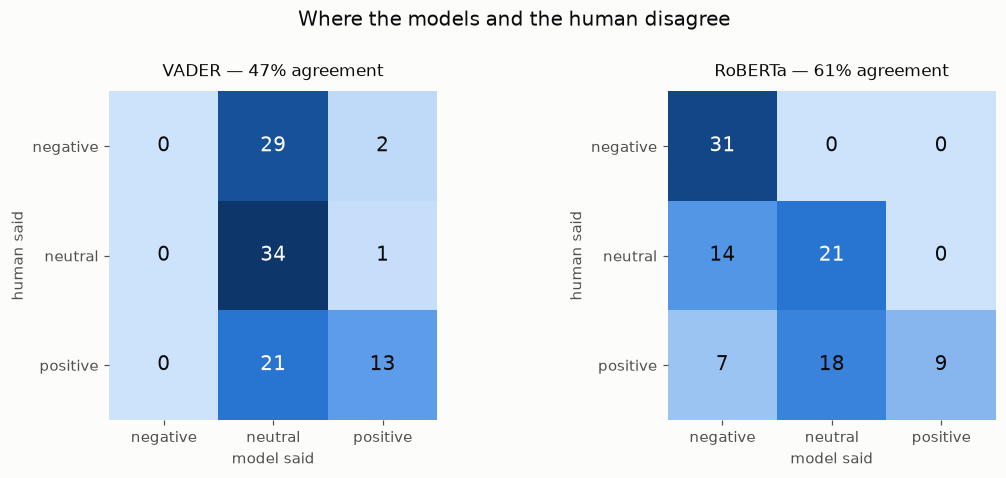

In [4]:
# --- Confusion matrices ---------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.3))

panels = [("VADER", "vader_label"), ("RoBERTa", "roberta_label")]
matrices = {n: confusion_matrix(df["human_label"], df[c], labels=LABELS)
            for n, c in panels}
# One colour scale across BOTH panels. Scaling each to its own max would make
# equal counts render as different shades and invite a false comparison.
vmax = max(m.max() for m in matrices.values())

for ax, (name, col) in zip(axes, panels):
    cm = matrices[name]
    ax.imshow(cm, cmap=BLUE_RAMP, vmin=0, vmax=vmax)

    # Direct value labels: a heatmap without numbers makes the reader guess.
    for r in range(len(LABELS)):
        for c in range(len(LABELS)):
            ax.text(c, r, cm[r, c], ha="center", va="center", fontsize=13,
                    # Ink flips on dark cells for contrast; never the series colour.
                    color="#ffffff" if cm[r, c] > vmax * 0.55 else INK)

    acc = (df[col] == df["human_label"]).mean()
    ax.set_title(f"{name} — {acc:.0%} agreement", color=INK, fontsize=11, pad=10)
    ax.set_xticks(range(3), LABELS)
    ax.set_yticks(range(3), LABELS)
    ax.set_xlabel("model said")
    ax.set_ylabel("human said")
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)

fig.suptitle("Where the models and the human disagree", fontsize=13, color=INK, y=1.0)
fig.tight_layout()
plt.show()

**Read the RoBERTa matrix along the top row.** Every one of the 31 conversations the
human called *negative*, the model also called negative — perfect recall on unhappy
customers. The errors are all below the diagonal: 14 *neutral* calls pushed to negative,
and 18 *positive* calls pushed down to neutral with another 7 all the way to negative.

Nothing sits above the diagonal. **The model is never too cheerful — it is only ever
too gloomy.**

In [5]:
# --- Is the error one-directional? ---------------------------------------
# Scattered errors are noise; errors that all point one way are a miscalibrated
# threshold, which is fixable without retraining.
rank = {"negative": 0, "neutral": 1, "positive": 2}

for name, col in [("VADER", "vader_label"), ("RoBERTa", "roberta_label")]:
    delta = df[col].map(rank) - df["human_label"].map(rank)
    print(f"{name:8s} | agree {int((delta == 0).sum()):3d} | "
          f"model gloomier {int((delta < 0).sum()):3d} | "
          f"model cheerier {int((delta > 0).sum()):3d}")

VADER    | agree  47 | model gloomier  21 | model cheerier  32
RoBERTa  | agree  61 | model gloomier  39 | model cheerier   0


## 2. Accuracy by topic

With 100 labels spread over 7 topics, each bar rests on 8–21 conversations, so these are
indicative rather than precise — the n is printed on every bar for that reason.

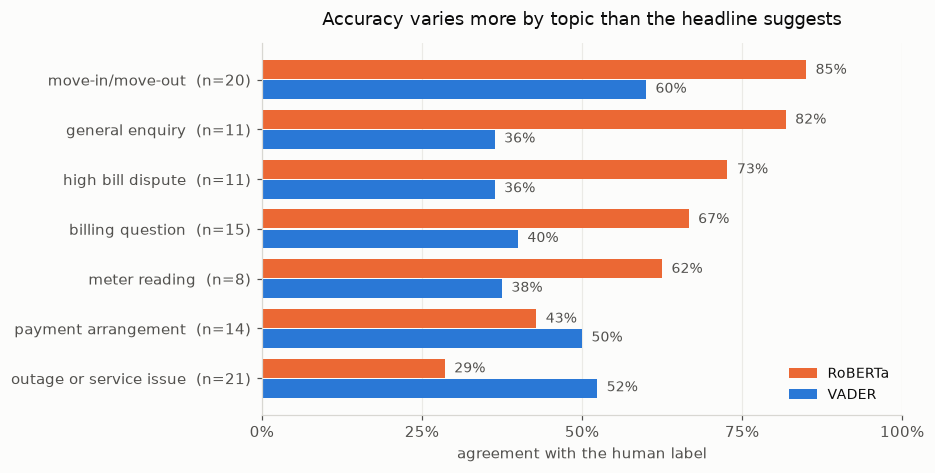

,VADER,RoBERTa,n
topic,,,
outage or service issue,52%,29%,21
payment arrangement,50%,43%,14
meter reading,38%,62%,8
billing question,40%,67%,15
high bill dispute,36%,73%,11
general enquiry,36%,82%,11
move-in/move-out,60%,85%,20


In [6]:
by_topic = (df.assign(
        VADER=df["vader_label"] == df["human_label"],
        RoBERTa=df["roberta_label"] == df["human_label"])
    .groupby("topic")
    .agg(VADER=("VADER", "mean"), RoBERTa=("RoBERTa", "mean"), n=("topic", "size"))
    .sort_values("RoBERTa"))

fig, ax = plt.subplots(figsize=(8.6, 4.4))
y = np.arange(len(by_topic))
h = 0.38
# 2px-equivalent gap between the paired bars so they never touch.
ax.barh(y + h / 2 + 0.012, by_topic["RoBERTa"], h, label="RoBERTa",
        color=SERIES["RoBERTa"])
ax.barh(y - h / 2 - 0.012, by_topic["VADER"], h, label="VADER",
        color=SERIES["VADER"])

for i, (_, row) in enumerate(by_topic.iterrows()):
    ax.text(row["RoBERTa"] + 0.015, i + h / 2, f"{row['RoBERTa']:.0%}",
            va="center", fontsize=9, color=INK_MUTED)
    ax.text(row["VADER"] + 0.015, i - h / 2, f"{row['VADER']:.0%}",
            va="center", fontsize=9, color=INK_MUTED)

ax.set_yticks(y, [f"{t}  (n={n})" for t, n in zip(by_topic.index, by_topic["n"])])
ax.set_xlim(0, 1.0)
ax.set_xticks(np.arange(0, 1.01, 0.25), ["0%", "25%", "50%", "75%", "100%"])
ax.set_xlabel("agreement with the human label")
ax.set_title("Accuracy varies more by topic than the headline suggests",
             fontsize=12, color=INK, pad=12)
ax.legend(frameon=False, loc="lower right", fontsize=9)
ax.xaxis.grid(True, color="#ebeae6", linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

by_topic.assign(VADER=lambda d: d.VADER.map("{:.0%}".format),
                RoBERTa=lambda d: d.RoBERTa.map("{:.0%}".format))

RoBERTa swings from **85% on move-in/move-out down to 29% on outages** — and on outages
the word-list beats the transformer. Outage calls open with a genuine complaint ("no
power, it's freezing") and frequently end satisfied once an ETA is given, so they are
exactly the shape the model handles worst. The next section shows why.

## 3. Five conversations the model got wrong, and why

Picked to span the distinct failure modes rather than the worst scores.
`start` and `end` are the model's own sentiment on the first and last third of the
customer's turns — printed because they turn out to be the whole story.

In [7]:
CASES = {
    "I01279": "Mixed arc. Opens furious about 12 months of estimated reads, ends "
              "genuinely grateful. Averaging the whole conversation buries the recovery.",
    "I00636": "Negation. 'Not panicking' and 'no gas smell' contain the negative words "
              "without the negative meaning; the model counts the words.",
    "I01379": "Negation plus filler. 'Nothing's wrong' reads as wrong, and the verbal tic "
              "'look, okay' scans as confrontational when it is just speech.",
    "I01661": "Short email, no counterweight. Three customer turns, one of which is a "
              "complaint, so a single sentence decides the whole label.",
    "I00933": "Hypothetical grievance. 'If it doesn't find an error, I'm still stuck with "
              "$270' is a conditional worry, not present anger — the customer is calm.",
}

for iid, why in CASES.items():
    row = df[df["interaction_id"] == iid].iloc[0]
    print("=" * 94)
    print(f"{iid}  ·  {row['topic']}  ·  {row['channel']}")
    print(f"human said {row['human_label'].upper()}  →  model said "
          f"{row['roberta_label'].upper()}   "
          f"(overall {row['roberta_score']:+.2f}; start {row['roberta_start']:+.2f} "
          f"→ end {row['roberta_end']:+.2f})")
    print(f"WHY: {why}\n")
    for line in row["transcript_text"].split("\n"):
        if line.startswith("Customer:"):
            print("   ", line[:150])
    print()

I01279  ·  meter reading  ·  voice
human said POSITIVE  →  model said NEGATIVE   (overall -0.73; start -0.90 → end +0.89)
WHY: Mixed arc. Opens furious about 12 months of estimated reads, ends genuinely grateful. Averaging the whole conversation buries the recovery.

    Customer: I mean, you've estimated my meter for 12 months straight and now you've hit me with a catch-up bill. That's not acceptable.
    Customer: I don't have the statement in front of me, but the address is 243 Cedarglen Road, Edmonton.
    Customer: Good, because the estimates have been nowhere close. I've been a customer for eleven years, by the way.
    Customer: There's a gate, yes, but it's not locked.
    Customer: That's great, thank you — you've been really helpful.

I00636  ·  outage or service issue  ·  voice
human said POSITIVE  →  model said NEUTRAL   (overall +0.20; start -0.59 → end +0.94)
WHY: Negation. 'Not panicking' and 'no gas smell' contain the negative words without the negative meaning; the mod

Look at the `end` figure in all five. Every single one is positive or near zero — which is
where the human landed. **The model already computes the right answer and then averages
it away.**

## 4. The fix: score the ending, not the average

"How did the customer feel about this contact?" is best answered by how they felt when
they hung up — not by averaging their opening complaint with their closing thanks.

Below, each candidate signal is converted to a label with a two-threshold band, and the
band is tuned on these 100 rows. Tuning on the same data you report would flatter the
result, so the honest number is the **cross-validated** one underneath: the band is fitted
on 80 rows and scored on the 20 it has not seen, five times over.

In [8]:
from itertools import product

def to_label(x, lo, hi):
    return np.where(x > hi, "positive", np.where(x < lo, "negative", "neutral"))

def best_band(signal, truth, grid_lo=np.arange(-0.9, 0.3, 0.05),
              grid_hi=np.arange(-0.3, 0.95, 0.05)):
    best = (0, None)
    for lo, hi in product(grid_lo, grid_hi):
        if lo >= hi:
            continue
        acc = (to_label(signal, lo, hi) == truth).mean()
        if acc > best[0]:
            best = (acc, (round(lo, 2), round(hi, 2)))
    return best

signals = {
    "whole conversation (current)": df["roberta_score"],
    "ending only": df["roberta_end"],
    "average of the two": (df["roberta_score"] + df["roberta_end"]) / 2,
}

rows = []
for name, sig in signals.items():
    acc, band = best_band(sig, df["human_label"])
    rows.append({"signal": name, "tuned accuracy": f"{acc:.0%}",
                 "band": f"{band[0]:+.2f} / {band[1]:+.2f}",
                 "kappa": round(cohen_kappa_score(
                     df["human_label"], to_label(sig, *band), labels=LABELS), 3)})
pd.DataFrame(rows).set_index("signal")

,tuned accuracy,band,kappa
signal,,,
whole conversation (current),65%,-0.55 / +0.05,0.479
ending only,81%,-0.25 / +0.90,0.713
average of the two,75%,-0.45 / +0.05,0.624


In [9]:
# --- Cross-validated: does the gain survive unseen data? ------------------
rng = np.random.default_rng(42)
folds = np.array_split(rng.permutation(len(df)), 5)

cv = {}
for name in ["whole conversation (current)", "ending only"]:
    sig, accs = signals[name], []
    for fold in folds:
        train = np.setdiff1d(np.arange(len(df)), fold)
        _, band = best_band(sig.iloc[train], df["human_label"].iloc[train])
        accs.append((to_label(sig.iloc[fold], *band)
                     == df["human_label"].iloc[fold]).mean())
    cv[name] = np.mean(accs)
    print(f"{name:32s} held-out accuracy {np.mean(accs):.0%}  "
          f"(folds: {', '.join(f'{a:.0%}' for a in accs)})")

print(f"\nImprovement on unseen data: "
      f"{cv['ending only'] - cv['whole conversation (current)']:+.0%}")

whole conversation (current)     held-out accuracy 56%  (folds: 50%, 70%, 45%, 60%, 55%)


ending only                      held-out accuracy 77%  (folds: 90%, 75%, 75%, 65%, 80%)

Improvement on unseen data: +21%


**77% versus 56% on data the thresholds never saw.** The gain is real, not an artefact of
fitting — and it needs no retraining, no GPU and no new model. It is a change to how an
existing number is read.

That still leaves roughly a quarter of conversations misread, which is why the
recommendation in `docs/validation.md` is to automate the confident cases and route the
rest to a person.

In [10]:
# --- What a confidence-based routing rule would cost ----------------------
# Only the rows where the model is sure are automated; the rest go to a human.
end = df["roberta_end"]
for cutoff in [0.0, 0.3, 0.5, 0.7]:
    confident = end.abs() >= cutoff
    if confident.sum() == 0:
        continue
    acc_conf = (to_label(end[confident], -0.25, 0.9)
                == df["human_label"][confident]).mean()
    print(f"auto-score when |end| >= {cutoff:.1f}: "
          f"covers {confident.mean():.0%} of contacts at {acc_conf:.0%} accuracy, "
          f"{(~confident).sum():3d} of 100 sent for human review")

auto-score when |end| >= 0.0: covers 100% of contacts at 81% accuracy,   0 of 100 sent for human review
auto-score when |end| >= 0.3: covers 84% of contacts at 82% accuracy,  16 of 100 sent for human review
auto-score when |end| >= 0.5: covers 71% of contacts at 85% accuracy,  29 of 100 sent for human review
auto-score when |end| >= 0.7: covers 59% of contacts at 83% accuracy,  41 of 100 sent for human review
